In [1]:
import os.path

import equations as eq
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pinner2026_jpo_code
import pinner2026_jpo_code.helper as helper

In [2]:
INTERIM_DATA_DIR = pinner2026_jpo_code.DATA_DIR / "interim"
DERIVED_DATA_DIR = pinner2026_jpo_code.DATA_DIR / "derived"

In [3]:
nsquared_data = helper.load_pickle(INTERIM_DATA_DIR / "nsquared_data_at_measurements.pkl")
nsquared_data_at_C = nsquared_data["C"][2350]
nsquared_data_at_C

2017-01-26    0.000002
2017-01-27    0.000002
2017-01-28    0.000001
2017-01-29    0.000003
2017-01-30    0.000002
                ...   
2019-01-25    0.000003
2019-01-26    0.000003
2019-01-27    0.000002
2019-01-28    0.000002
2019-01-29    0.000002
Freq: D, Name: 2350, Length: 734, dtype: float64

In [4]:
def get_mean_N_squared_in_chunk(chunk_time_index, N_squared_series):

    try:
        assert N_squared_series.index[0] <= pd.to_datetime(chunk_time_index[0])
        assert N_squared_series.index[-1] >= pd.to_datetime(chunk_time_index[-1])
        return N_squared_series.loc[chunk_time_index[0] : chunk_time_index[-1]].mean()

    # requested chunk is outside the given time series
    except AssertionError as e:
        print(
            "FROM: available:",
            N_squared_series.index[0],
            "requested:",
            chunk_time_index[0],
            N_squared_series.index[0] - chunk_time_index[0],
        )
        print("TO: available:", N_squared_series.index[-1], "requested:", chunk_time_index[-1])

        # time difference is small, proceed anyway
        if np.abs(N_squared_series.index[0] - chunk_time_index[0]) < pd.Timedelta(days=1):
            return N_squared_series.loc[chunk_time_index[0] : chunk_time_index[-1]].mean()

        else:
            raise e
            # return np.nan

In [5]:
# available_energy_df = pd.read_csv(INTERIM_DATA_DIR / "available_energy.csv", index_col=0)
# available_energy_df

In [6]:
# for index, energy in available_energy_df.iterrows():

#     _, indexa, _, indexb, _  = index.split("'")
#     print(pd.to_datetime(indexa) - pd.to_datetime(indexb))

In [7]:
latitude_at_mooring_C = -63.66
CORIOLIS_FREQUENCY_IN_CPD = helper.get_coriolis_frequency(
    latitude_at_mooring_C, unit="cpd", absolute=True
)
CORIOLIS_FREQUENCY_IN_CPD
coriolis_frequency_in_rads = helper.get_coriolis_frequency(
    latitude_at_mooring_C, unit="rad/s", absolute=True
)

In [8]:
DERIVED_DISSIP_FILE = DERIVED_DATA_DIR / "wave_induced_dissipation_rate_time_series_at_C.csv"

if not os.path.isfile(DERIVED_DISSIP_FILE):
    time_stamps = []
    dissipation_rates = []

    for index, energy in available_energy_df.iterrows():
        _, indexa, _, indexb, _ = index.split("'")
        mean_N_squared_in_rads = get_mean_N_squared_in_chunk((indexa, indexb), nsquared_data_at_C)
        mean_N_in_rads = np.sqrt(mean_N_squared_in_rads)

        assert len(energy) == 1
        energy = energy.iloc[0]

        eps = eq.calculate_dissipation_rate(
            coriolis_frequency=coriolis_frequency_in_rads,
            buoyancy_frequency=mean_N_in_rads,
            energy_level=energy,
        )
        a = pd.to_datetime(indexa)
        b = pd.to_datetime(indexb)
        time_stamps.append(a + (b - a) / 2)  # time stamp in the middle of chunk
        dissipation_rates.append(eps)

    dissipation_rate_time_series = pd.Series(index=time_stamps, data=dissipation_rates)
    dissipation_rate_time_series.to_csv(DERIVED_DISSIP_FILE)
    print("dissip saved")

else:
    dissipation_rate_time_series = pd.read_csv(DERIVED_DISSIP_FILE, index_col=0)
    print("dissip loaded")

dissipation_rate_time_series

dissip loaded


,0
2017-02-12,8.252667e-10
2017-02-17,8.708783e-10
2017-02-22,8.313334e-10
2017-02-27,9.406800e-10
2017-03-04,1.544095e-09
...,...
2018-12-24,9.840217e-10
2018-12-29,1.178971e-09
2019-01-03,1.208642e-09
2019-01-08,1.308510e-09


In [9]:
surface_stress = pd.read_csv(INTERIM_DATA_DIR / "daily_momentum_transfer.csv")
surface_stress = surface_stress.set_index(pd.to_datetime(surface_stress["Unnamed: 0"]))
surface_stress = surface_stress.drop("Unnamed: 0", axis="columns")
# momentum_transfer = momentum_transfer.loc[smoothed_hke.index[0]:]
for _i, col in enumerate(surface_stress.columns):
    surface_stress[col] = surface_stress[col].str.replace("i", "j").apply(lambda x: complex(x))
surface_stress["C"]

Unnamed: 0
2017-01-03   -0.017194-0.016066j
2017-01-08   -0.020871+0.005411j
2017-01-13    0.002699+0.014019j
2017-01-18    0.005724+0.036860j
2017-01-23   -0.001701-0.000736j
                     ...        
2019-12-09         NaN+0.000000j
2019-12-14         NaN+0.000000j
2019-12-19         NaN+0.000000j
2019-12-24         NaN+0.000000j
2019-12-29         NaN+0.000000j
Name: C, Length: 219, dtype: complex128

TypeError: tz must be string or tzinfo subclass, not <matplotlib.category.UnitData object at 0x000002750E922A50>.

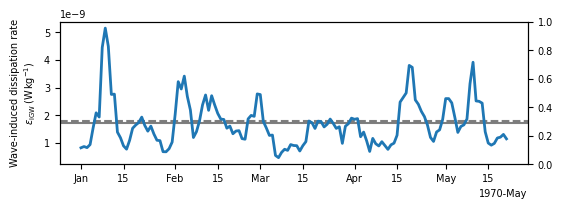

In [10]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 7})

fig, ax = plt.subplots(1, figsize=(14 * cm, 5 * cm), layout="constrained")

result_of_Pinner2025 = 1.7809504867405678e-09
l_paper = ax.axhline(
    result_of_Pinner2025,
    color="black",
    ls="--",
    label="$\\overline{\\varepsilon_\\text{IGW}}$",
    alpha=0.5,
)
l_avrg = ax.axhline(
    np.mean(dissipation_rate_time_series),
    ls="-",
    label="$\\langle\\varepsilon_\\text{IGW}(t)\\rangle$",
    color="black",
    alpha=0.5,
)
(l_eps,) = ax.plot(
    dissipation_rate_time_series.index,
    dissipation_rate_time_series.to_numpy(),
    label="$\\varepsilon_\\text{IGW}(t)$",
    lw=2,
)
ax.set_ylabel("Wave-induced dissipation rate\n$\\varepsilon_{\\mathrm{IGW}}\\,$(W$\\,$kg$^{-1}$)")

locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

ax2 = ax.twinx()
ax2.set_zorder(-1)
ax.set_facecolor("None")
(l_tau,) = ax2.plot(surface_stress["C"].abs(), color="tab:red", label="$\\tau(t)$", lw=2)
ax2.set_ylabel("surface stress\n$|\\tau|$ / (N$\\,$m$^{-2}$)")

ax.legend(
    handles=[l_eps, l_avrg, l_paper, l_tau],
    title="measured at mooring C, 2350$\\,$m depth, 143$\\,$mab",
    ncol=4,
    fontsize=6,
    framealpha=0.9,
)
# fig.savefig("dissipation_rate_at_mooring_C.pdf")

In [13]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 7})

# plt.rcParams.update({
#     "pgf.texsystem": "pdflatex",
#     'text.usetex': True,
#     'pgf.rcfonts': False,
# })

fig, ax = plt.subplots(1, figsize=(14 * cm, 5 * cm), layout="constrained")

result_of_Pinner2025 = 1.7809504867405678e-09
l_paper = ax.axhline(result_of_Pinner2025, color="black", ls="--", label="Pinner2025", alpha=0.5)
l_avrg = ax.axhline(
    np.mean(dissipation_rate_time_series),
    ls="-",
    label="$\\langle\varepsilon_\text{IGW}(t)\rangle$",
    color="black",
    alpha=0.5,
)
(l_eps,) = ax.plot(
    dissipation_rate_time_series.index,
    dissipation_rate_time_series.to_numpy(),
    label="$\varepsilon_\text{IGW}(t)$",
    lw=2,
)
ax.set_ylabel(
    "Wave-induced dissipation rate\newline$\varepsilon_{\\mathrm{IGW}}\\,$(\\mathrm{W}$\\,$kg$^{-1}$)"
)

locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

ax2 = ax.twinx()
ax2.set_zorder(-1)
ax.set_facecolor("None")
(l_tau,) = ax2.plot(surface_stress["C"].abs(), color="tab:red", label="$\tau(t)$", lw=2)
ax2.set_ylabel("surface stress\n$|\tau|$ / (N$\\,$m$^{-2}$)")

ax.legend(
    handles=[l_eps, l_avrg, l_paper, l_tau],
    title=r"measured at mooring C, 2350$\,$m depth, 143$\,$mab",
    ncol=4,
    fontsize=6,
    framealpha=0.9,
)
# fig.savefig("dissipation_rate_at_mooring_C.pgf")

TypeError: tz must be string or tzinfo subclass, not <matplotlib.category.UnitData object at 0x0000027513955F90>.

Error in callback <function _draw_all_if_interactive at 0x000002750B9001A0> (for post_execute), with arguments args (),kwargs {}:


ValueError: 
ewline$arepsilon_{\mathrm{IGW}}\,$(\mathrm{W}$\,$kg$^{-1}$)
      ^
ParseException: Expected end of text, found '$'  (at char 6), (line:1, col:7)

ValueError: 
ewline$arepsilon_{\mathrm{IGW}}\,$(\mathrm{W}$\,$kg$^{-1}$)
      ^
ParseException: Expected end of text, found '$'  (at char 6), (line:1, col:7)

<Figure size 551.181x196.85 with 2 Axes>

In [ ]:
# plt.plot(dissipation_rate_time_series.index,".")
# plt.plot(surface_stress["C"].index,".")
print(dissipation_rate_time_series.index)
print(surface_stress["C"].index[8:])